# 02 — Preprocesamiento

**Escenario 4:** Efectividad de campañas de marketing
**Dataset:** Bank Marketing (UCI) — `bank-additional-full.csv`

En este notebook se limpian y transforman los datos según lo encontrado en el EDA (notebook 01). Al final se guardan dos archivos en `data/processed/`:

- `bank_clean.csv`: datos limpios y codificados, **sin escalar**. Se usa en el modelo supervisado (el escalado se hace después de separar train/test para no filtrar información del conjunto de prueba).
- `bank_scaled.csv`: datos limpios, codificados y **estandarizados**, sin la variable `y`. Se usa en PCA, que necesita que todas las variables estén en la misma escala.

## 0. Librerías y carga de datos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/raw/bank-additional-full.csv", sep=";")
print("Tamaño original:", df.shape)

Tamaño original: (41188, 21)


## 1. Eliminar duplicados

En el EDA se encontraron 12 filas repetidas. Se eliminan porque no aportan información nueva y podrían hacer que un mismo registro quede en train y en test a la vez.

In [2]:
antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Filas eliminadas: {antes - len(df)}")
print("Tamaño actual:", df.shape)

Filas eliminadas: 12
Tamaño actual: (41176, 21)


## 2. Eliminar `duration`

`duration` es la duración de la última llamada en segundos. Aunque es la variable que más se relaciona con `y`, este dato solo se conoce después de llamar al cliente, y cuando la llamada termina ya se sabe si aceptó o no. Si se deja en el modelo, el resultado se vería muy bueno pero no serviría en la práctica. Los autores del dataset recomiendan quitarla si se quiere un modelo realista.

In [3]:
df = df.drop(columns=["duration"])
print("Columnas actuales:", df.shape[1])

Columnas actuales: 20


## 3. Transformar `pdays`

`pdays` indica cuántos días pasaron desde el último contacto de una campaña anterior. El valor 999 significa que el cliente nunca fue contactado, y eso pasa en el 96,3% de los registros. Si se deja así, el 999 se tomaría como un número muy grande y confundiría a los modelos.

Se reemplaza por una variable binaria `contactado_antes` (1 = sí fue contactado antes, 0 = nunca).

In [4]:
df["contactado_antes"] = (df["pdays"] != 999).astype(int)
df = df.drop(columns=["pdays"])
print(df["contactado_antes"].value_counts())

contactado_antes
0    39661
1     1515
Name: count, dtype: int64


## 4. Tratar los valores `unknown`

Se tomaron dos decisiones distintas según la variable:

| Variable | % unknown | Decisión | Motivo |
|---|---|---|---|
| `default` | 20,9% | Convertir a binaria `default_no` | Hay demasiados unknown para imputar y solo existen 3 casos `yes`. Además, en el EDA los `unknown` tienen menor conversión (5,2%) que los `no` (12,9%), así que el hecho de no saber el dato ya da información. |
| `education`, `housing`, `loan`, `job`, `marital` | menos de 5% | Imputar con la moda | Son pocos registros, así que reemplazarlos por el valor más frecuente casi no cambia la distribución. |

In [5]:
print("Conversión según default:")
print(df.groupby("default")["y"].apply(lambda s: (s == "yes").mean() * 100).round(1))

df["default_no"] = (df["default"] == "no").astype(int)
df = df.drop(columns=["default"])

Conversión según default:
default
no         12.9
unknown     5.2
yes         0.0
Name: y, dtype: float64


In [6]:
imputar = ["education", "housing", "loan", "job", "marital"]
for col in imputar:
    moda = df.loc[df[col] != "unknown", col].mode()[0]
    n = (df[col] == "unknown").sum()
    df[col] = df[col].replace("unknown", moda)
    print(f"{col}: {n} valores 'unknown' reemplazados por '{moda}'")

print("\n¿Quedan 'unknown'?", (df == "unknown").sum().sum())

education: 1730 valores 'unknown' reemplazados por 'university.degree'
housing: 990 valores 'unknown' reemplazados por 'yes'
loan: 990 valores 'unknown' reemplazados por 'no'
job: 330 valores 'unknown' reemplazados por 'admin.'
marital: 80 valores 'unknown' reemplazados por 'married'

¿Quedan 'unknown'? 0


## 5. Codificar variables categóricas

Los modelos solo trabajan con números, así que las variables de texto se convierten así:

- **Binarias** (solo dos valores): `housing`, `loan` y `contact` → 0 / 1.
- **Ordinal:** `education`, porque sus categorías tienen un orden natural (de analfabeto a título universitario).
- **One-Hot Encoding:** `job`, `marital`, `month`, `day_of_week` y `poutcome`, porque sus categorías no tienen orden. Se usa `drop_first=True` para evitar columnas redundantes.

In [7]:
# Binarias
df["housing"] = (df["housing"] == "yes").astype(int)
df["loan"] = (df["loan"] == "yes").astype(int)
df["contact_cellular"] = (df["contact"] == "cellular").astype(int)
df = df.drop(columns=["contact"])

# Ordinal
orden_educacion = {
    "illiterate": 0, "basic.4y": 1, "basic.6y": 2, "basic.9y": 3,
    "high.school": 4, "professional.course": 5, "university.degree": 6,
}
df["education"] = df["education"].map(orden_educacion)
print("education:", sorted(df["education"].unique()))

education: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [8]:
onehot = ["job", "marital", "month", "day_of_week", "poutcome"]
df = pd.get_dummies(df, columns=onehot, drop_first=True, dtype=int)
print("Columnas después de One-Hot:", df.shape[1])

Columnas después de One-Hot: 42


## 6. Codificar la variable objetivo

`y` se convierte a número: `yes` = 1 (aceptó) y `no` = 0 (no aceptó).

In [9]:
df["y"] = (df["y"] == "yes").astype(int)
print(df["y"].value_counts())

y
0    36537
1     4639
Name: count, dtype: int64


## 7. Verificación del dataset limpio

In [10]:
print("Tamaño final:", df.shape)
print("Valores nulos:", df.isna().sum().sum())
print("Columnas de texto restantes:", df.select_dtypes(exclude="number").columns.tolist())
df.head()

Tamaño final: (41176, 42)
Valores nulos: 0
Columnas de texto restantes: []


,age,education,housing,loan,campaign,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,contactado_antes,default_no,contact_cellular,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_married,marital_single,month_aug,month_dec,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56,1,0,0,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
1,57,4,0,0,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
2,37,4,1,0,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
3,40,2,0,0,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0
4,56,4,0,1,1,0,1.1,93.994,-36.4,4.857,5191.0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0


## 8. Estandarización

Las variables numéricas tienen escalas muy distintas (por ejemplo `nr.employed` está cerca de 5.000 y `previous` va de 0 a 7). PCA trabaja con varianzas, así que sin escalar las variables más grandes dominarían el resultado.

Se usa `StandardScaler`, que deja cada variable con media 0 y desviación estándar 1:

$$z = \frac{x - \mu}{\sigma}$$

Para este archivo no se incluye `y`, porque PCA es no supervisado y no debe usar la etiqueta.

In [11]:
X = df.drop(columns=["y"])
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

comparacion = pd.DataFrame({
    "media_antes": X[["age", "campaign", "nr.employed", "euribor3m"]].mean(),
    "desv_antes": X[["age", "campaign", "nr.employed", "euribor3m"]].std(),
    "media_despues": X_scaled[["age", "campaign", "nr.employed", "euribor3m"]].mean(),
    "desv_despues": X_scaled[["age", "campaign", "nr.employed", "euribor3m"]].std(),
}).round(3)
comparacion

,media_antes,desv_antes,media_despues,desv_despues
age,40.024,10.421,0.0,1.0
campaign,2.568,2.770,0.0,1.0
nr.employed,5167.035,72.251,0.0,1.0
euribor3m,3.621,1.734,-0.0,1.0


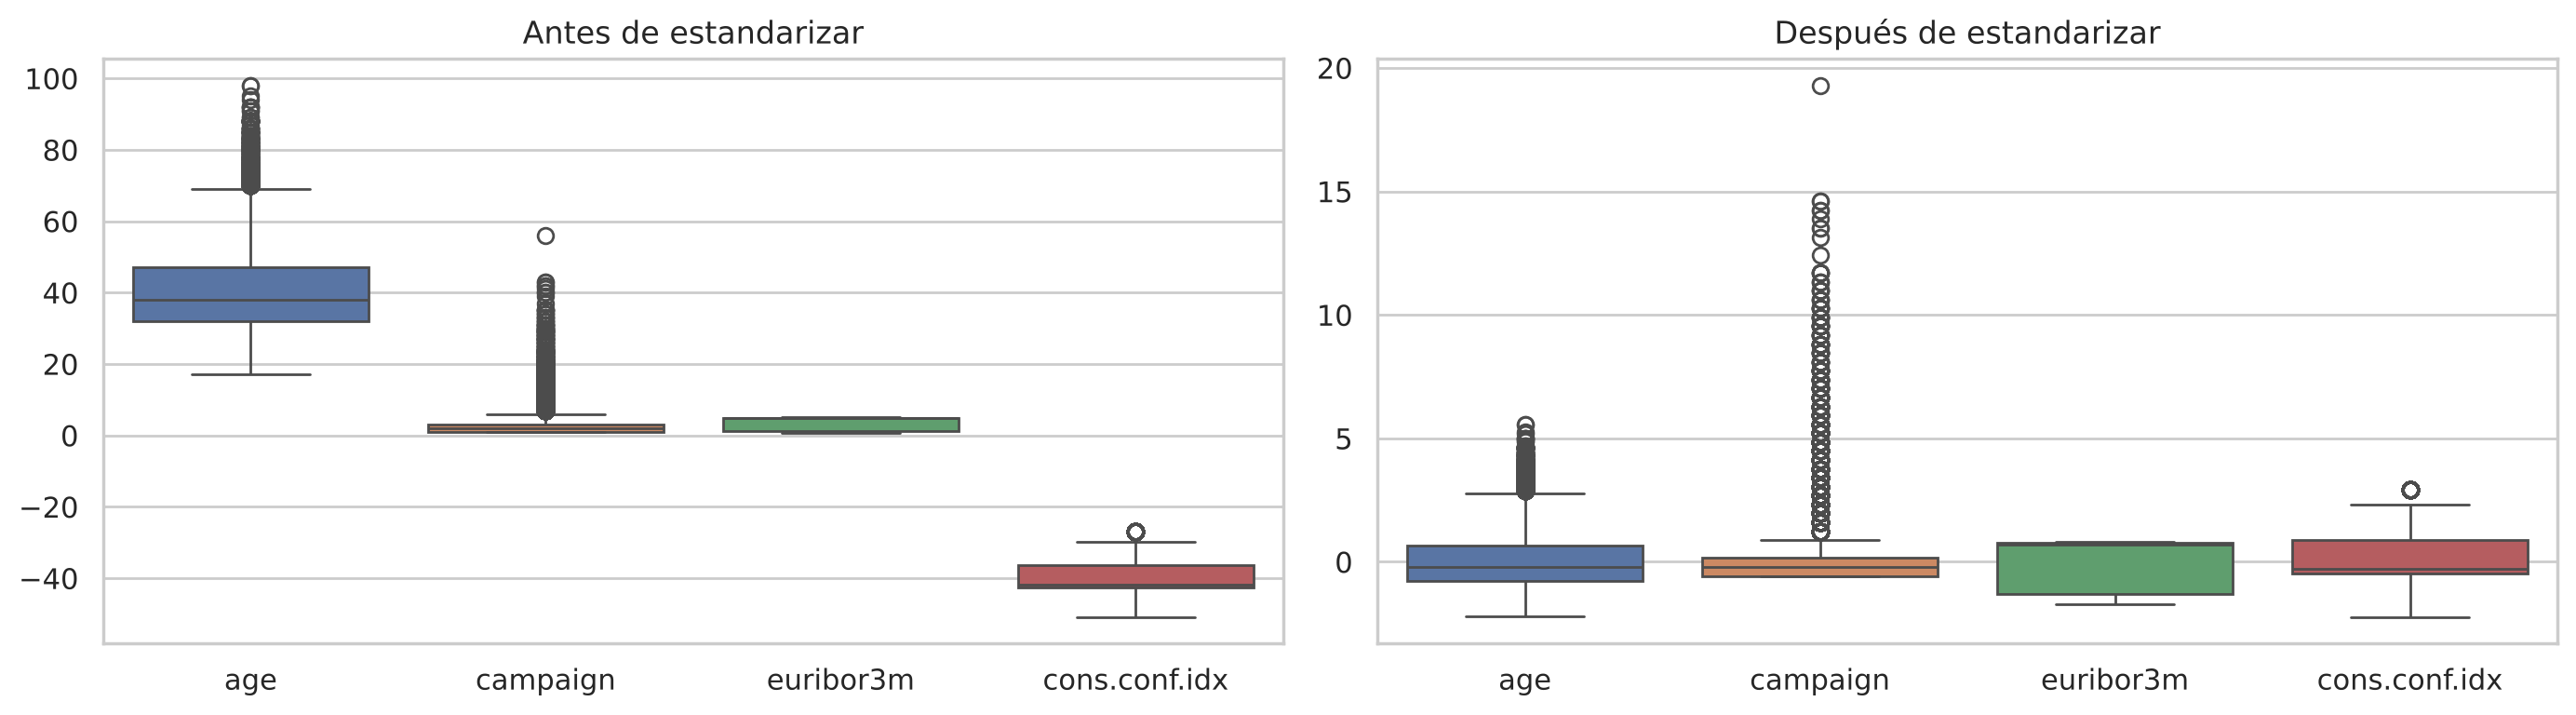

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
cols = ["age", "campaign", "euribor3m", "cons.conf.idx"]
sns.boxplot(data=X[cols], ax=axes[0])
axes[0].set_title("Antes de estandarizar")
sns.boxplot(data=X_scaled[cols], ax=axes[1])
axes[1].set_title("Después de estandarizar")
plt.tight_layout()
plt.show()

## 9. Guardar los datos procesados

In [13]:
df.to_csv("../data/processed/bank_clean.csv", index=False)
X_scaled.to_csv("../data/processed/bank_scaled.csv", index=False, float_format="%.6f")

print("bank_clean.csv  ->", df.shape)
print("bank_scaled.csv ->", X_scaled.shape)

bank_clean.csv  -> (41176, 42)
bank_scaled.csv -> (41176, 41)


## 10. Resumen del preprocesamiento

| Paso | Qué se hizo | Por qué |
|---|---|---|
| Duplicados | Se eliminaron 12 filas | Registros repetidos |
| `duration` | Se eliminó | Solo se conoce después de la llamada (fuga de información) |
| `pdays` | Se cambió por `contactado_antes` (0/1) | El 999 no es un valor real |
| `default` | Se cambió por `default_no` (0/1) | 20,9% unknown y solo 3 casos `yes` |
| `unknown` en otras variables | Se imputaron con la moda | Menos del 5% en cada variable |
| Binarias | `housing`, `loan`, `contact` → 0/1 | Solo tienen dos valores |
| `education` | Codificación ordinal (0 a 6) | Tiene un orden natural |
| Nominales | One-Hot en `job`, `marital`, `month`, `day_of_week`, `poutcome` | No tienen orden |
| `y` | yes → 1, no → 0 | Variable objetivo numérica |
| Escalado | `StandardScaler` (solo en `bank_scaled.csv`) | Necesario para PCA |

Los valores atípicos de `campaign`, `previous` y `age` se mantuvieron porque son datos reales y no errores de registro.